# Pivot trees on different data types

A pivot tree splits on the distance from *pivots*, instances of the training set, so its rules can be read by looking at the pivots themselves, whatever the data are. Two kinds of pivot splits are shown here:

- `PivotTreeStumpClassifier`: `P_a <= t`, the instances closer than `t` to the pivot `a` go left;
- `ProximityPivotTreeStumpClassifier`: `P_a <= P_b`, the instances closer to the pivot `a` than to the pivot `b` go left, the others right. There is no threshold: each child is described by a pivot, usually of different classes.

The pivot stumps work on vectors: they take tabular data, and time series (`X_ts`) and images (`X_img`) flattened into one feature per value; with an `embedder`, they compare the embeddings of the instances instead, and take also texts (`X_txt`). The distances are computed on the standardized vectors (categorical features one-hot encoded).

The pivots of time series, images and texts are kept as given to `fit`: `plot_tree` draws the rules as text by default, and with `show_media=True` the pivots too, below the rule of their node or, for the proximity pivot stumps, on the arrows of the two children. All the trees here have depth 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from RuleTree import RuleTreeClassifier
from RuleTree.stumps.classification import PivotTreeStumpClassifier, ProximityPivotTreeStumpClassifier


def pivot_tree(stump, y_train, **data):
    """A tree of depth 2 with the given pivot stump, trained on the data given as in fit (X, X_ts, X_img)."""
    return RuleTreeClassifier(max_depth=2, random_state=0, base_stumps=stump).fit(y=y_train, **data)

## Tabular data

The iris flowers: four measures of each flower. Here the pivots are drawn on two of the measures, with larger markers: a star for the pivot of each node of the pivot tree, and a dashed line joining the two pivots compared by each node of the proximity pivot tree.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3, stratify=iris.target,
                                                    random_state=0)

pivot_model = pivot_tree(PivotTreeStumpClassifier(), y_train, X=X_train)
proximity_model = pivot_tree(ProximityPivotTreeStumpClassifier(), y_train, X=X_train)
for name, model in [("pivot", pivot_model), ("proximity pivot", proximity_model)]:
    print(f"{name} tree, accuracy {accuracy_score(y_test, model.predict(X_test)):.3f}")
    model.print_rules(model.get_rules())

pivot tree, accuracy 0.844
|--- P_54 <= 2.985
|   |--- P_50 <= 1.332
|   |    output: 1
|   |--- P_50 > 1.332
|        output: 2
|--- P_54 > 2.985
     output: 0
proximity pivot tree, accuracy 0.822
|--- P_26 <= P_54
|    output: 0
|--- P_26 > P_54
    |--- P_9 <= P_50
    |    output: 2
    |--- P_9 > P_50
         output: 1


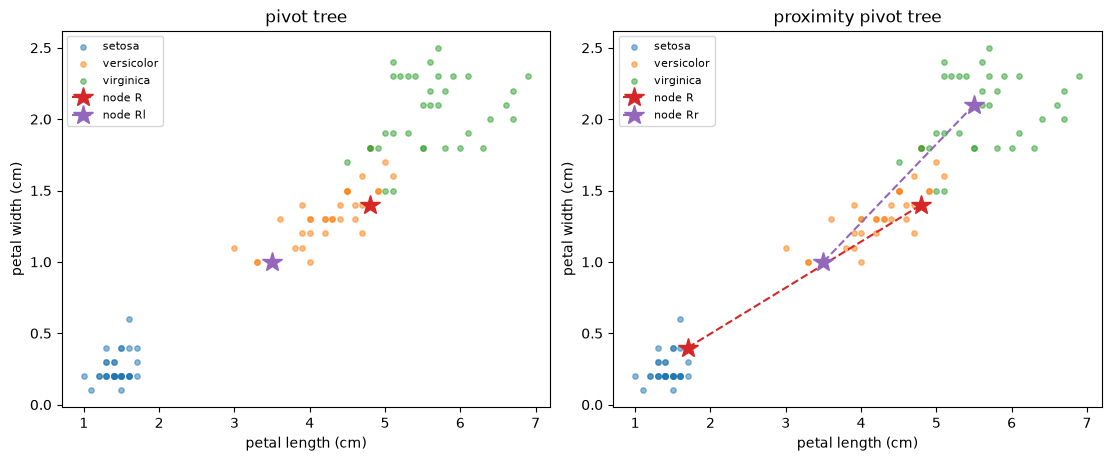

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, (title, model) in zip(axes, [("pivot tree", pivot_model), ("proximity pivot tree", proximity_model)]):
    for label, name in enumerate(iris.target_names):
        ax.scatter(*X_train[y_train == label][:, 2:].T, s=15, alpha=0.5, label=name)
    for k, (node_id, node) in enumerate(model.get_predicates().items()):
        used = node.stump.get_pivots()["used"]
        pivots = X_train[used if isinstance(used, list) else [used], 2:]
        ax.plot(*pivots.T, "--*", color=f"C{k + 3}", markersize=15, label=f"node {node_id}")
    ax.set_title(title)
    ax.set_xlabel(iris.feature_names[2])
    ax.set_ylabel(iris.feature_names[3])
    ax.legend(fontsize=8)
plt.show()

## Images

The handwritten digits of scikit-learn: images of 8 x 8 pixels, given as `X_img` (the pivot stumps flatten them into 64 values). A tree of depth 2 has at most four leaves, so the example keeps four digits. A pivot is an image, so a rule reads as "closer than *t* to this digit" or "closer to this digit than to that one"; `plot_tree(show_media=True)` draws the pivots as images.

pivot tree, accuracy: 0.718


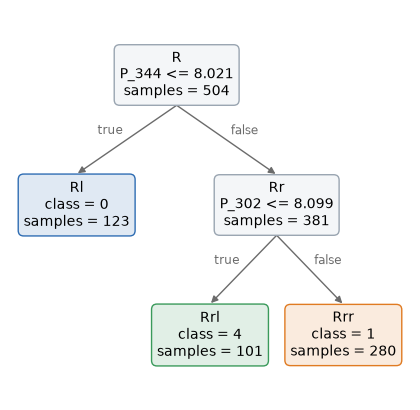

In [4]:
from sklearn.datasets import load_digits

digits = load_digits()
four = np.isin(digits.target, [0, 1, 4, 7])
images = digits.images[four]
images_train, images_test, y_train, y_test = train_test_split(images, digits.target[four], test_size=0.3,
                                                              stratify=digits.target[four], random_state=0)
pivot_model = pivot_tree(PivotTreeStumpClassifier(), y_train, X_img=images_train)
print("pivot tree, accuracy:", round(accuracy_score(y_test, pivot_model.predict(X_img=images_test)), 3))
pivot_model.plot_tree()  # the rules only, as text
plt.show()

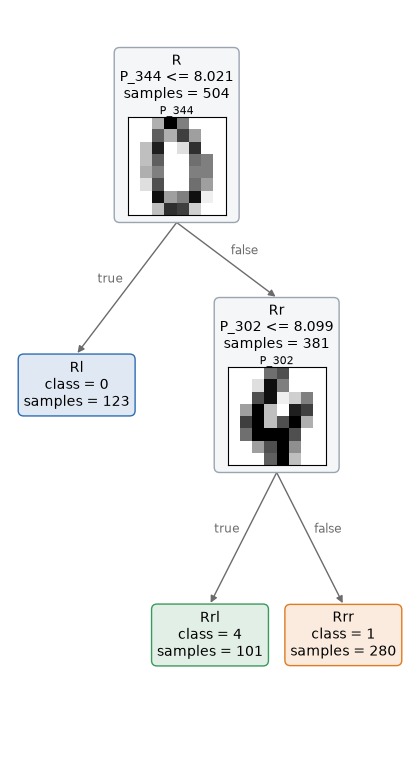

In [5]:
pivot_model.plot_tree(show_media=True)
plt.show()

proximity pivot tree, accuracy: 0.727


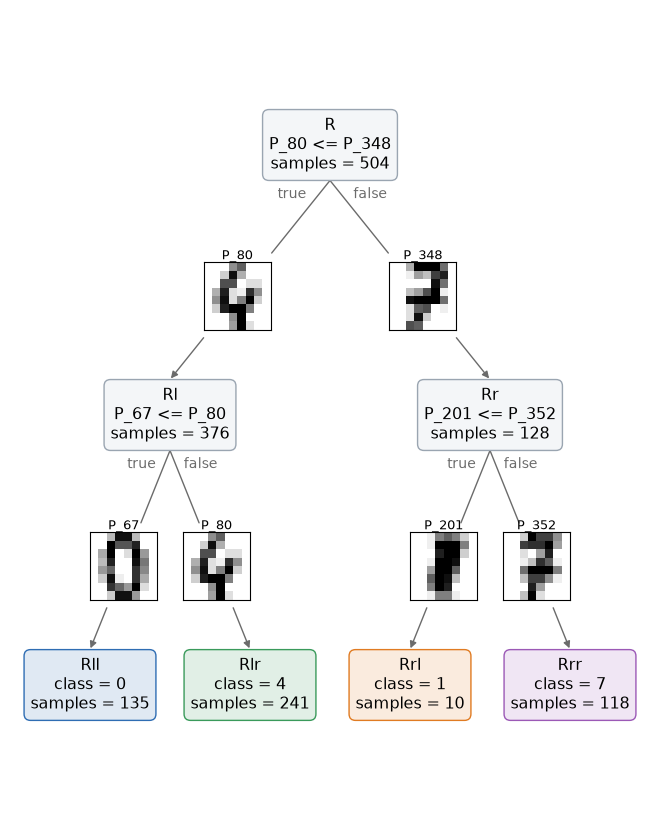

In [6]:
proximity_model = pivot_tree(ProximityPivotTreeStumpClassifier(), y_train, X_img=images_train)
print("proximity pivot tree, accuracy:", round(accuracy_score(y_test, proximity_model.predict(X_img=images_test)), 3))
proximity_model.plot_tree(show_media=True)
plt.show()

## Time series

The Cylinder-Bell-Funnel data set (Saito, 1994), a classic synthetic benchmark of time series classification: each series is noise plus a plateau (cylinder), an increasing ramp (bell) or a decreasing ramp (funnel), starting and ending at random times. The series of 128 values are given as `X_ts`, of shape (series, signals, length), and a pivot is a whole series.

pivot tree, accuracy: 0.844


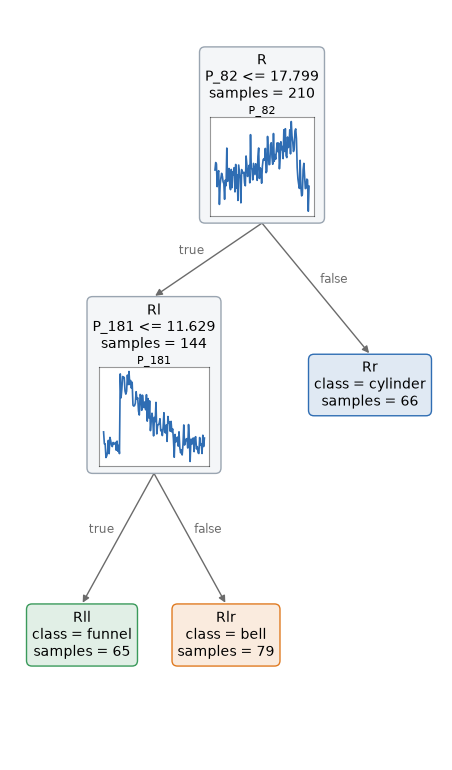

In [7]:
def cylinder_bell_funnel(n_per_class, length=128, seed=0):
    """The Cylinder-Bell-Funnel time series (Saito, 1994)."""
    rng = np.random.default_rng(seed)
    t = np.arange(length)
    series, labels = [], []
    for label in range(3):
        for _ in range(n_per_class):
            a = rng.integers(16, 32)
            b = a + rng.integers(32, 96)
            inside = (t >= a) & (t <= b)
            shape = inside * [1.0, (t - a) / (b - a), (b - t) / (b - a)][label]
            series.append((6 + rng.normal()) * shape + rng.normal(size=length))
            labels.append(label)
    return np.array(series), np.array(labels)


cbf_names = ["cylinder", "bell", "funnel"]
X_ts, y_ts = cylinder_bell_funnel(100)
X_train, X_test, y_train, y_test = train_test_split(X_ts[:, None, :], y_ts, test_size=0.3, stratify=y_ts,
                                                    random_state=0)

pivot_model = pivot_tree(PivotTreeStumpClassifier(), y_train, X_ts=X_train)
print("pivot tree, accuracy:", round(accuracy_score(y_test, pivot_model.predict(X_ts=X_test)), 3))
pivot_model.plot_tree(class_names=cbf_names, show_media=True)
plt.show()

proximity pivot tree, accuracy: 0.833


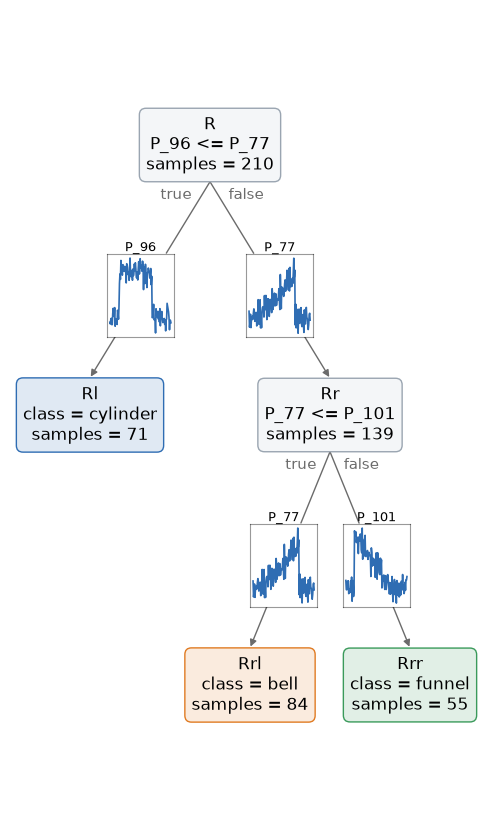

In [8]:
proximity_model = pivot_tree(ProximityPivotTreeStumpClassifier(), y_train, X_ts=X_train)
print("proximity pivot tree, accuracy:", round(accuracy_score(y_test, proximity_model.predict(X_ts=X_test)), 3))
proximity_model.plot_tree(class_names=cbf_names, show_media=True)
plt.show()

## Texts

Texts are given as `X_txt` to pivot stumps with an `embedder`. The paper embeds them with a sentence transformer (`RuleTree.utils.embeddings.TextEmbedder`, which needs the `embeddings` extra). To keep this example self-contained, the embedder here is scikit-learn's `HashingVectorizer`, which is stateless: each sentence becomes the counts of its words, on a small corpus of sentences about two topics. The pivots are sentences of the training set, drawn by `plot_tree(show_media=True)`.

In [9]:
rng = np.random.default_rng(0)
topics = {
    "sport": (["The striker", "Our goalkeeper", "The coach", "The home team", "That runner", "The referee"],
              ["scored a late goal", "won the final match", "trained on the pitch", "lost the derby",
               "broke the record at the stadium", "celebrated the championship"]),
    "cooking": (["My grandmother", "The chef", "This recipe", "The bakery", "Our cook", "That pastry"],
                ["baked fresh bread", "needs garlic and olive oil", "simmered the tomato sauce",
                 "served a warm soup", "uses butter and flour", "roasted vegetables in the oven"]),
}
texts, text_labels = [], []
for topic, (subjects, predicates) in topics.items():
    for _ in range(60):
        texts.append(f"{rng.choice(subjects)} {rng.choice(predicates)}.")
        text_labels.append(topic)
texts, text_labels = np.array(texts), np.array(text_labels)
texts_train, texts_test, y_train, y_test = train_test_split(texts, text_labels, test_size=0.3,
                                                            stratify=text_labels, random_state=0)

pivot tree, accuracy: 0.833


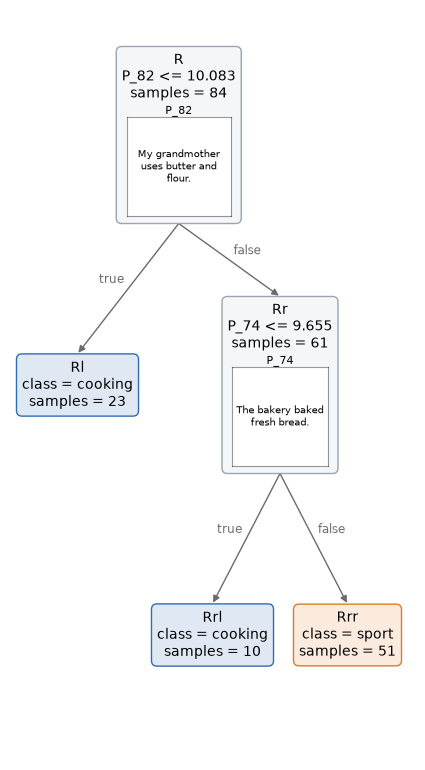

In [10]:
from sklearn.feature_extraction.text import HashingVectorizer

embedder = HashingVectorizer(n_features=256, alternate_sign=False)  # the counts of the words, hashed

pivot_model = pivot_tree(PivotTreeStumpClassifier(embedder=embedder), y_train, X_txt=texts_train)
print("pivot tree, accuracy:", round(accuracy_score(y_test, pivot_model.predict(X_txt=texts_test)), 3))
pivot_model.plot_tree(show_media=True)
plt.show()

proximity pivot tree, accuracy: 0.722


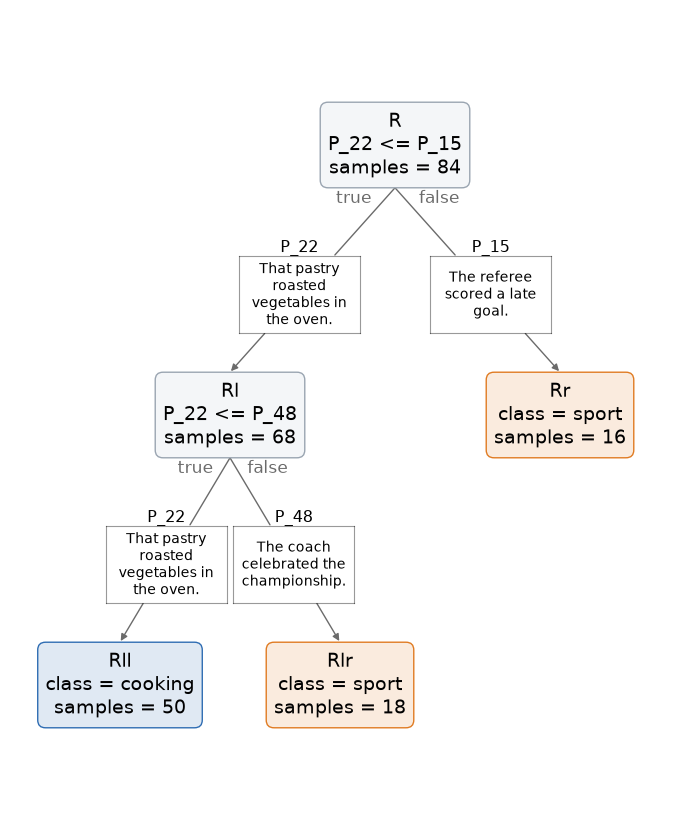

In [11]:
proximity_model = pivot_tree(ProximityPivotTreeStumpClassifier(embedder=embedder), y_train, X_txt=texts_train)
print("proximity pivot tree, accuracy:", round(accuracy_score(y_test, proximity_model.predict(X_txt=texts_test)), 3))
proximity_model.plot_tree(show_media=True)
plt.show()

## Reading a prediction

The path of an instance is a sequence of comparisons with the pivots. Here, for a sentence of the test set, the two pivots compared by each node of the proximity pivot tree it crosses, and the side it goes to: towards the pivot it is closer to.

In [12]:
sentence = texts_test[:1]
print(repr(str(sentence[0])))
leaf = proximity_model.apply(X_txt=sentence)[0]
node = proximity_model.root
while not node.is_leaf():
    closer, farther = (node.stump.transformer_.media_[pivot] for pivot in node.stump.get_pivots()["used"])
    goes_left = leaf.startswith(node.node_id + "l")
    if not goes_left:
        closer, farther = farther, closer
    print(f"  node {node.node_id}: closer to {closer!r} than to {farther!r} -> {'left' if goes_left else 'right'}")
    node = node.node_l if goes_left else node.node_r
print("prediction:", proximity_model.predict(X_txt=sentence)[0])

'The bakery served a warm soup.'
  node R: closer to 'That pastry roasted vegetables in the oven.' than to 'The referee scored a late goal.' -> left
  node Rl: closer to 'That pastry roasted vegetables in the oven.' than to 'The coach celebrated the championship.' -> left
prediction: cooking
